# Part I - (FORD GOBIKE USAGE PATTERNS)
## by (Siddhant Maksare)

## Introduction
This project explores 183,412 bike-sharing trips recorded through the Ford GoBike system in the San Francisco Bay Area during February 2019. The dataset contains information about trip duration, start and end times, station locations, user type, and selected member demographics. By examining these variables, the analysis aims to identify patterns in bike usage, including when and where trips occur, how riding behavior differs between subscribers and occasional customers, and which factors influence trip duration. The findings can provide insight into how the bike-sharing system serves different users and how demand changes across locations and time periods.

In [1]:
# import all packages and set plots to be embedded inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
bikes = pd.read_csv("Downloads/201902-fordgobike-tripdata.csv")
bikes.head()

,duration_sec,start_time,end_time,start_station_id,start_station_name,start_station_latitude,start_station_longitude,end_station_id,end_station_name,end_station_latitude,end_station_longitude,bike_id,user_type,member_birth_year,member_gender,bike_share_for_all_trip
0,52185,2019-02-28 17:32:10.1450,2019-03-01 08:01:55.9750,21.0,Montgomery St BART Station (Market St at 2nd St),37.789625,-122.400811,13.0,Commercial St at Montgomery St,37.794231,-122.402923,4902,Customer,1984.0,Male,No
1,42521,2019-02-28 18:53:21.7890,2019-03-01 06:42:03.0560,23.0,The Embarcadero at Steuart St,37.791464,-122.391034,81.0,Berry St at 4th St,37.775880,-122.393170,2535,Customer,NaN,NaN,No
2,61854,2019-02-28 12:13:13.2180,2019-03-01 05:24:08.1460,86.0,Market St at Dolores St,37.769305,-122.426826,3.0,Powell St BART Station (Market St at 4th St),37.786375,-122.404904,5905,Customer,1972.0,Male,No
3,36490,2019-02-28 17:54:26.0100,2019-03-01 04:02:36.8420,375.0,Grove St at Masonic Ave,37.774836,-122.446546,70.0,Central Ave at Fell St,37.773311,-122.444293,6638,Subscriber,1989.0,Other,No
4,1585,2019-02-28 23:54:18.5490,2019-03-01 00:20:44.0740,7.0,Frank H Ogawa Plaza,37.804562,-122.271738,222.0,10th Ave at E 15th St,37.792714,-122.248780,4898,Subscriber,1974.0,Male,Yes


In [3]:
#high level overview of data shape and composition
print(bikes.shape)
print(bikes.dtypes)

(183412, 16)
duration_sec                 int64
start_time                  object
end_time                    object
start_station_id           float64
start_station_name          object
start_station_latitude     float64
start_station_longitude    float64
end_station_id             float64
end_station_name            object
end_station_latitude       float64
end_station_longitude      float64
bike_id                      int64
user_type                   object
member_birth_year          float64
member_gender               object
bike_share_for_all_trip     object
dtype: object


In [4]:
bikes.isnull().sum()

duration_sec                  0
start_time                    0
end_time                      0
start_station_id            197
start_station_name          197
start_station_latitude        0
start_station_longitude       0
end_station_id              197
end_station_name            197
end_station_latitude          0
end_station_longitude         0
bike_id                       0
user_type                     0
member_birth_year          8265
member_gender              8265
bike_share_for_all_trip       0
dtype: int64

In [5]:
#Function 
def format_plot(ax, title, xlabel, ylabel):
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)

### What is the structure of your dataset?

> The data is in tabular CSV format. Where each row represents one individual bike trip and each column describes an attribute of that trip. it contains 183412 trip records and 16 variables.
> The dataset includes numerical, categorical, geographic variables. The member_birth_year and member_gender each column contains 8265 values missing. There are 197 station values are missing too. 

### What is/are the main feature(s) of interest in your dataset?

> The main feature of interest are trip duration and bike usage patterns.I want to investigate how long trips typically last and how usage changes according to the time of day, day of the week, user type, location, and rider characteristics.

### What features in the dataset do you think will help support your investigation into your feature(s) of interest?

> duration_sec: measures the length of each trip and serves as the primary outcome variable.

> start_time and end_time: can be used to examine hourly and daily patterns including difference between weekday and weekends

> user_type: supports comparisons between subscribers and occasional customers.

> station names & Id: helps identifying frequently used starting stations, destination stations and routes

> members birth year and gender: supports investigation among different demographic groups. Age can be derived from the birth year.

> Together, these variables can help explain when, where, how long and by whom the bike-sharing system was used. 

## Univariate Exploration

## Data Preparation 

In [6]:
#convert timestamps 
bikes["start_time"] = pd.to_datetime(bikes["start_time"])
bikes["end_time"] = pd.to_datetime(bikes["end_time"])

#Create useful variables
bikes["duration_min"] = bikes["duration_sec"] / 60
bikes["start_hour"] = bikes["start_time"].dt.hour
bikes["start_day"] = bikes["start_time"].dt.day_name()
bikes["age"] = 2019 - bikes["member_birth_year"]

day_order = [ "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
bikes.shape

(183412, 20)

## Question

**What is distribution of trip durations? Are there usually long trips?**

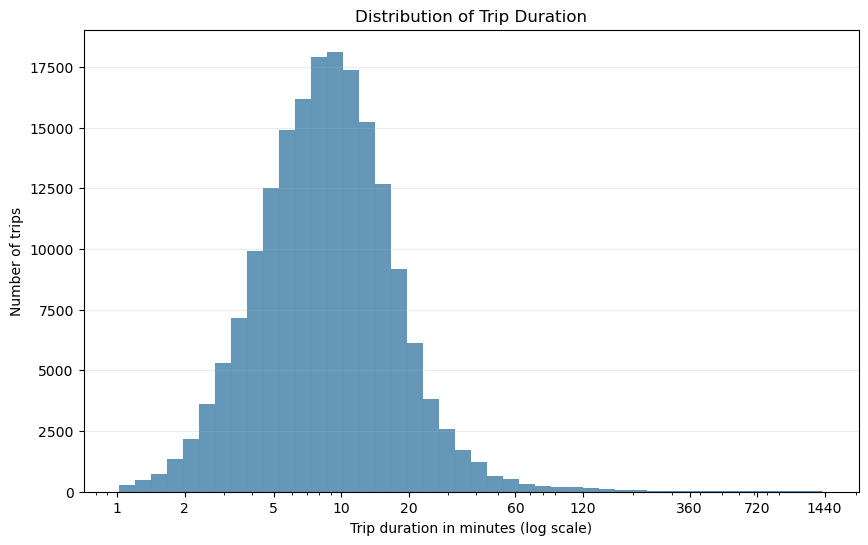

In [7]:
#Visualization 
bins = np.logspace(
    np.log10(bikes["duration_min"].min()),
    np.log10(bikes["duration_min"].max()),
    45
)

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(data=bikes,
            x="duration_min",
            bins=bins,
            color="#3274A1",
             ax=ax
            )

plt.xscale("log")
ticks = [1, 2, 5, 10, 20, 60, 120, 360, 720, 1440]
plt.xticks(ticks, ticks)

format_plot(
    ax,
    "Distribution of Trip Duration",
    "Trip duration in minutes (log scale)",
    "Number of trips"
)
plt.show()

1% of trips are skweing the visualization, so we will focus on 99% of trips to find the mean and median duration of trip to answer the question are there usually long trips

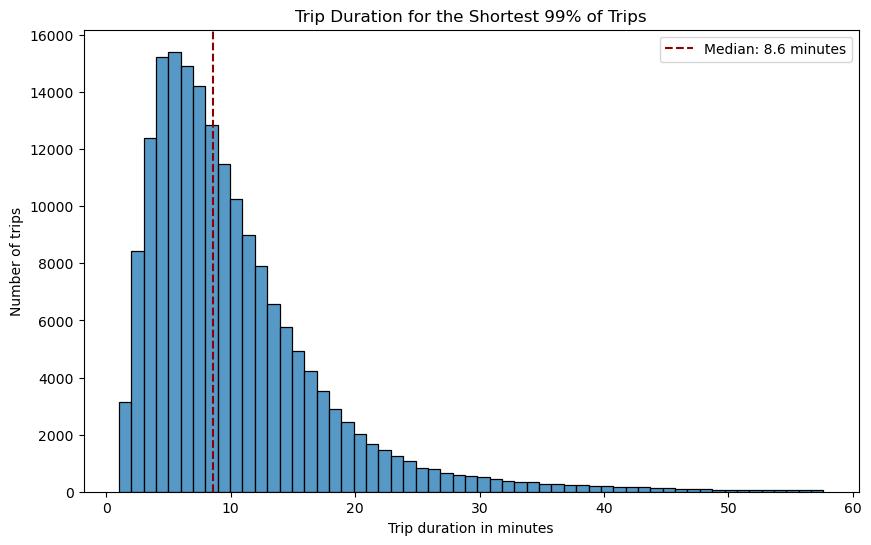

In [8]:
duration_99 = bikes["duration_min"].quantile(0.99)

plt.figure(figsize=(10, 6))

sns.histplot(data = bikes[bikes["duration_min"] <= duration_99],
            x="duration_min",
            binwidth=1)

plt.axvline(
    bikes["duration_min"].median(),
    color="darkred",
    linestyle="--",
    label = f"Median: {bikes["duration_min"].median():.1f} minutes")


plt.title("Trip Duration for the Shortest 99% of Trips")
plt.xlabel("Trip duration in minutes")
plt.ylabel("Number of trips")
plt.legend()
plt.show()

In [9]:
print(bikes["duration_min"].mean())
print(bikes["duration_min"].quantile(0.99))
print(bikes["duration_min"].max())

12.10130725724962
57.64816666666641
1424.0666666666666


## OBSERVATIONS 

- Trip Duration is strongly right-skewed.
- The median trip last 8.6minutes, while mean is about 12.1minutes.
- Approx 99% of trips last no more than 57.6minutes.
- The longest recorded trip lasts approximately 1424minutes (23.7hours)
- The long trips shouldn't be deleted automatically because they may represent legitimate rentals. A logarithmic scale or a 99th percentile viewing limits make the distribution easier to interpret without altering the original data. 

## QUESTION 
**How does the number of trips change across the week?**

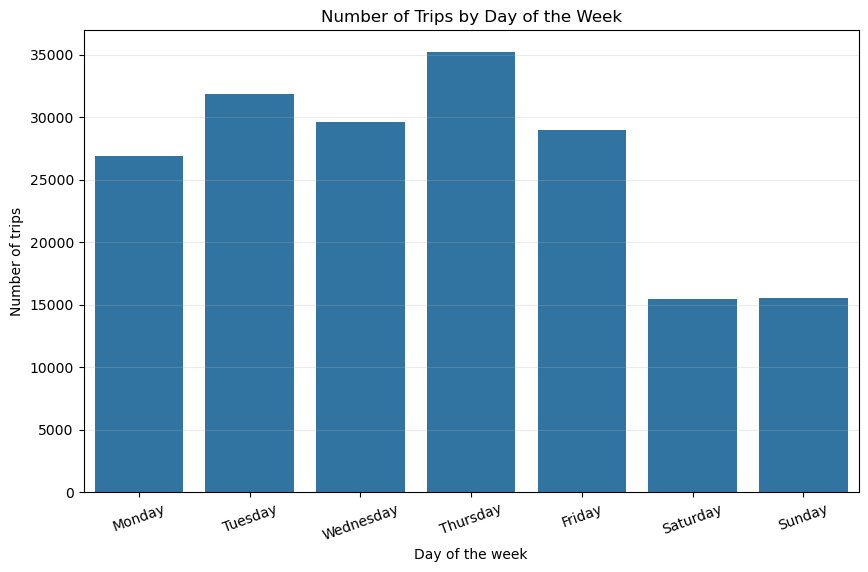

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.countplot(data=bikes,
                  x="start_day", 
                  order=day_order,
                  ax=ax)
format_plot(
    ax,
    "Number of Trips by Day of the Week",
    "Day of the week",
    "Number of trips"
)

plt.xticks(rotation=20)
plt.show()

## OBSERVATIONS 

- Thursday has the highest number of trips
- Saturday and Sunday has the lowest counts
- Most of the trips occur on weekdays.
- The strong weekday pattern suggest that many people use system for commuting and routine travel 

### Discuss the distribution(s) of your variable(s) of interest. Were there any unusual points? Did you need to perform any transformations?

> Trip duration had a strongly right-skewed distribution. Most trips were short and concentrated below one hour, while a small number lasted several hours. The longest trip was approximately 23.7 hours, creating a long tail in the distribution. A logarithmic scale was used to make both the common short trips and the unusually long trips visible.

> The number of trips also varied across the week. Weekdays recorded considerably more trips than weekends. Thursday had the highest number of trips, while Saturday and Sunday had the lowest. This pattern suggests that the service was commonly used for weekday commuting.

### Of the features you investigated, were there any unusual distributions? Did you perform any operations on the data to tidy, adjust, or change the form of the data? If so, why did you do this?

> Several data-preparation operations were performed before creating the visualizations. Trip duration was converted from seconds to minutes so that the values would be easier to interpret. The `start_time` column was converted from text to a date-time data type, and the day of the week was extracted into a new variable. The days were then arranged from Monday to Sunday instead of being displayed alphabetically.

> The original long-duration records were retained because there was not enough evidence to classify them as errors. Instead of removing them, the visualization was adjusted using a logarithmic scale to reduce their effect on the readability of the distribution.

# Bivariate Exploration

## Trip duration over time: scatter plot

**A sample is used to reduce overplotting The logarithmic y axis makes long trip visible without compressing the short ones.**

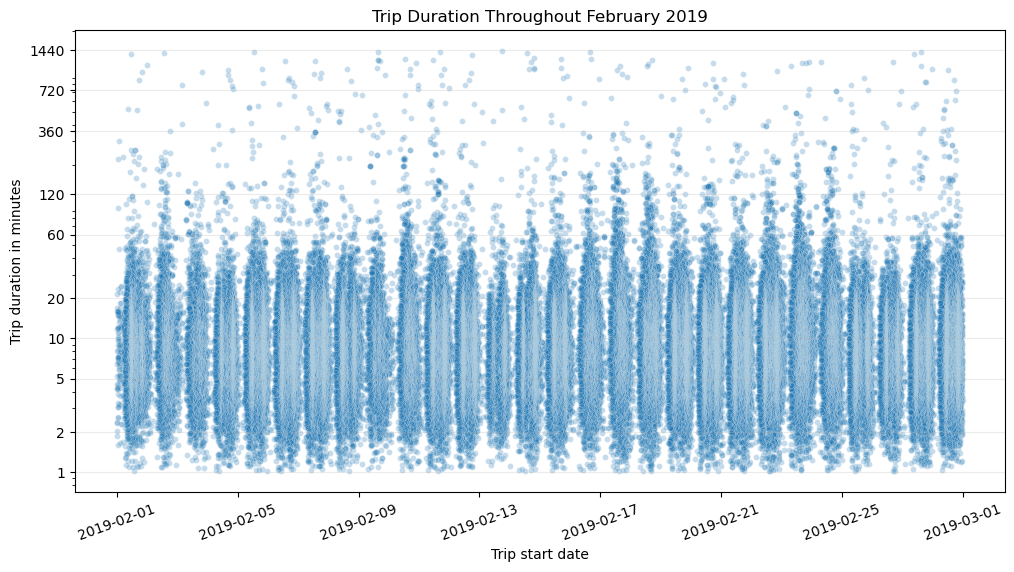

In [11]:
#Visualization 
plot_sample = bikes.sample(5000, random_state=42)

fig, ax = plt.subplots(figsize=(12, 6))

sns.scatterplot(data=bikes, 
               x="start_time", 
               y="duration_min", 
               alpha=0.25,
               s=18,
               ax=ax)

plt.yscale("log")
format_plot(
    ax,
    "Trip Duration Throughout February 2019",
    "Trip start date",
    "Trip duration in minutes"
)
plt.xticks(rotation=20)
ticks = [1, 2, 5, 10, 20, 60, 120, 360, 720, 1440]
plt.yticks(ticks, ticks)
plt.show()

## OBSERVATIONS

Trip durations were distributed throughout the month without a clear increasing or decreasing trend. Most trips remained relatively short on all dates. The unusually long trips were scattered across the month rather than concentrated within a particular period.

## Trip duration by day: box plot

**Does typical trip duration differ by day of week?**

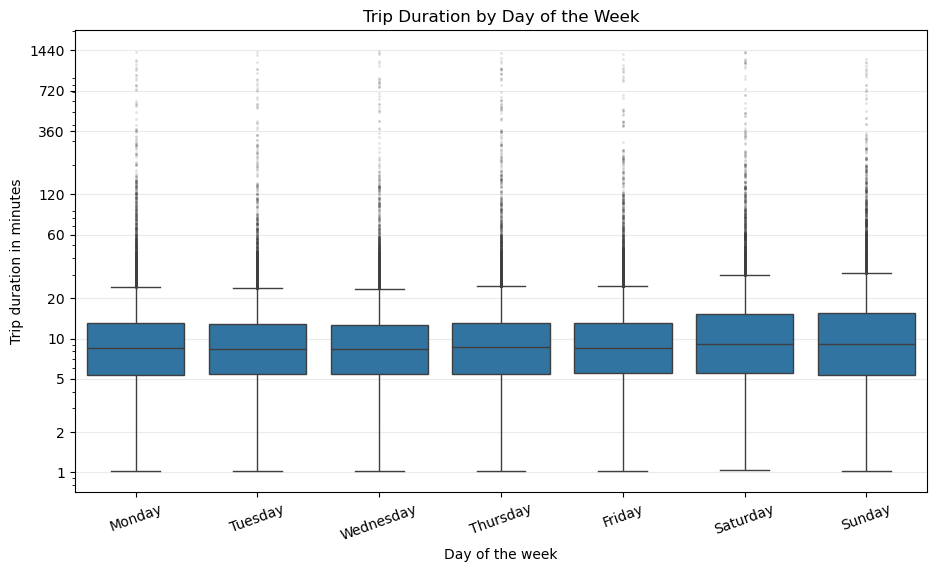

In [12]:
#Visualization 

fig, ax = plt.subplots(figsize=(11, 6))

sns.boxplot(data=bikes,
           x="start_day",
           y="duration_min", 
           order=day_order,
            ax=ax,
            flierprops={
                "marker": "o",
                "markersize": 1,
                "alpha": 0.15
            }
           )

plt.yscale("log")
format_plot(
    ax,
    "Trip Duration by Day of the Week",
    "Day of the week",
    "Trip duration in minutes"
)
plt.xticks(rotation=20)
ticks = [1, 2, 5, 10, 20, 60, 120, 360, 720, 1440]
plt.yticks(ticks, ticks)
plt.show()

In [13]:
#Mean duration for each day. 
mean_duration_by_day = (
    bikes.groupby("start_day")["duration_min"].mean()
    .reindex(day_order)
    .round(2)
)
print(mean_duration_by_day)

start_day
Monday       11.89
Tuesday      11.06
Wednesday    11.23
Thursday     11.65
Friday       11.60
Saturday     15.04
Sunday       15.33
Name: duration_min, dtype: float64


## OBSERVATIONS 

Typical trip durations were similar across the week. The weekday median was approximately 8.4–8.6 minutes, while the median on Saturday and Sunday was approximately 9.1 minutes. Weekend trips were therefore slightly longer. Weekend mean durations were around 15 minutes, compared with approximately 11–12 minutes on weekdays, indicating more long-duration trips on weekends.

## Duration category by day: clustered bar chart

**Does the proportion of short and long trips change across the week?**

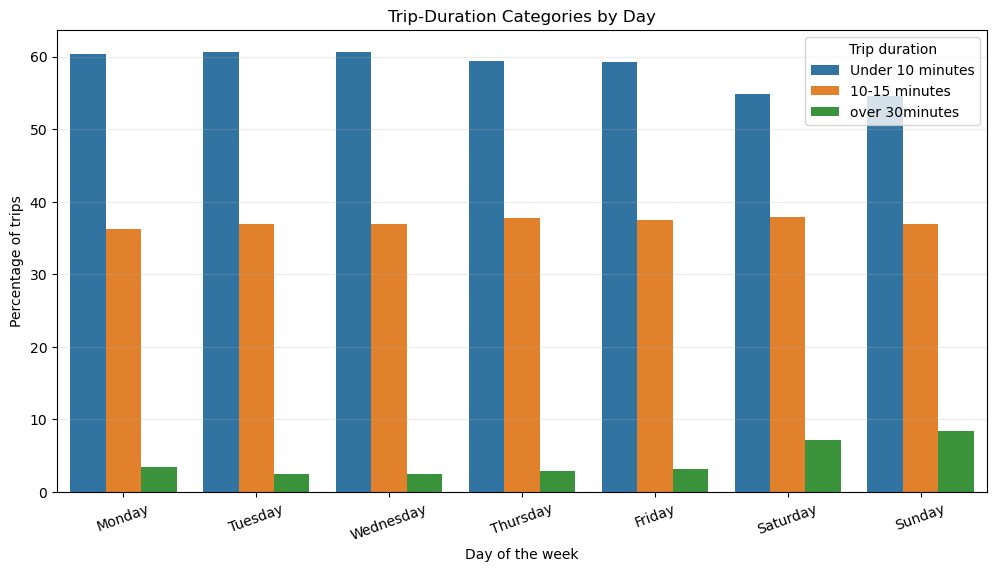

In [14]:
#Visualization 
bikes["duration_group"] = pd.cut(bikes["duration_min"], 
                                bins=[0, 10, 30, np.inf],
                                labels = ["Under 10 minutes", "10-15 minutes", "over 30minutes"],
                                right=False)

duration_day = (pd.crosstab(bikes["start_day"],
                           bikes["duration_group"],
                           normalize="index")
               .mul(100)
               .reindex(day_order)
               .reset_index()
               .melt(id_vars="start_day",
                    var_name="duration_group",
                    value_name="Percentage"
                    )
               )

fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=duration_day,
    x="start_day",
    y="Percentage",
    hue="duration_group",
    order=day_order,
    ax=ax
)

format_plot(
    ax,
    "Trip-Duration Categories by Day",
    "Day of the week",
    "Percentage of trips"
)
plt.xticks(rotation=20)
plt.legend(title="Trip duration")
plt.show()

## Observations

Short trips were the most common category on every day. Approximately 59–61% of weekday trips lasted under 10 minutes, compared with about 55% on weekends. Trips longer than 30 minutes represented only 2–3% of most weekday trips, but increased to 7.2% on Saturday and 8.4% on Sunday. This supports the finding that weekend users tend to take longer trips.

### Talk about some of the relationships you observed in this part of the investigation. How did the feature(s) of interest vary with other features in the dataset?

> Trip duration varied slightly across the days of the week. Weekday trips had median durations of approximately 8.4–8.6 minutes, while Saturday and Sunday trips had a median of about 9.1 minutes. Weekend trips also had higher mean durations and a greater proportion of trips lasting more than 30 minutes. This suggests that weekday trips were generally shorter and may have been routine journeys, while weekend trips were more likely to be longer recreational rides. Trip duration did not show a clear increasing or decreasing pattern over the month.

### Did you observe any interesting relationships between the other features (not the main feature(s) of interest)?

> An interesting relationship was observed between the day of the week and the number of trips. Weekdays had substantially more trips than weekends, with Thursday recording the highest usage and Saturday and Sunday recording the lowest. Although weekends had fewer trips, they had a larger proportion of long-duration rides. This contrast suggests that weekday usage was driven more by frequent short trips, while weekend usage involved fewer but generally longer trips.

# Multivariate Exploration

The third variable we will add is user_type to determine whether the relationship between trip duration and day of the week differes between subscribers and customers. 

## Data Preparation

In [15]:
bikes["day_type"] = np.where(bikes["start_time"].dt.dayofweek < 5, "Weekday", "Weekend")

bikes["day_type"] = pd.Categorical(bikes["day_type"], categories=["Weekday", "Weekend"], ordered=True)

## Duration distribution by user type and day type: facet plot

**Question: Do customers and subscribers have different trip-duration distributions on weekdays and weekends?**

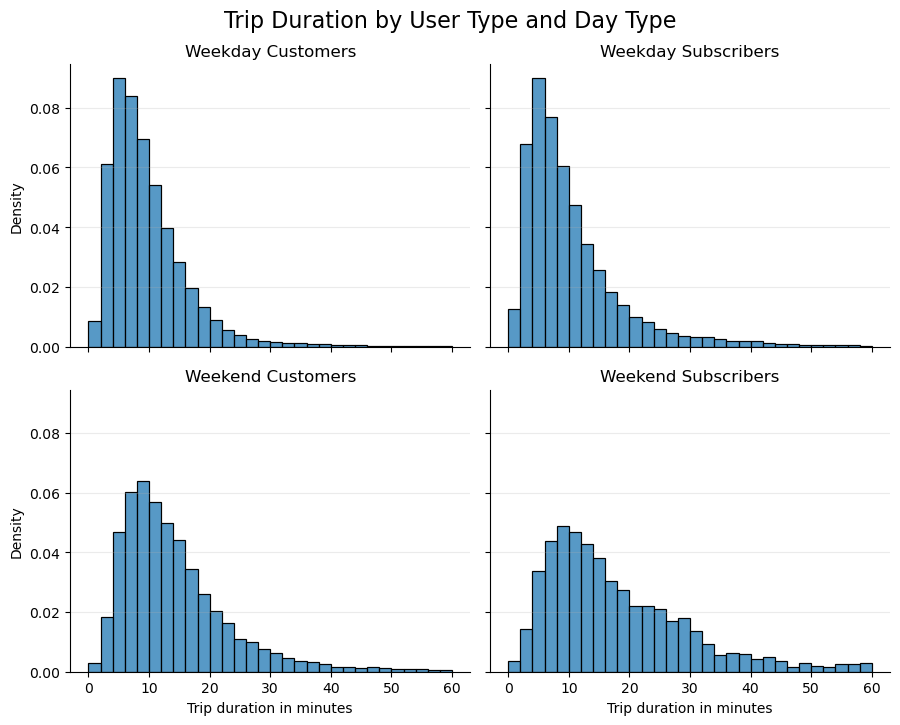

In [16]:
#Visualization Facet plot.

#We will change the displayed range to be focused on trips duration of 60minutes or less so the main distribution remain visible. 
duration_view = bikes[bikes["duration_min"] <=60]

g = sns.displot(
    data=duration_view, 
    x="duration_min",
    row="user_type",
    col="day_type",
    bins = np.arange(0, 62, 2),
    stat="density",
    common_norm=False,
    height=3.5, 
    aspect=1.3
)

facet_titles = [
    "Weekday Customers",
    "Weekday Subscribers",
    "Weekend Customers",
    "Weekend Subscribers"
]

for ax, title in zip(g.axes.flat, facet_titles):
    format_plot(
        ax,
        title,
        "Trip duration in minutes",
        "Density"
    )

g.figure.suptitle(
    "Trip Duration by User Type and Day Type",
    fontsize=16,
    y=1.03
)

plt.show()

In [17]:
#Calculating median for each combination
median_duration = duration_view.groupby(["user_type", "day_type"], observed=True)["duration_min"].median()
print(median_duration)

user_type   day_type
Customer    Weekday     12.033333
            Weekend     14.875000
Subscriber  Weekday      8.150000
            Weekend      8.083333
Name: duration_min, dtype: float64


## Observations 

Subscribers trips had a consistently narrow distribution concentrated around short durations. Their median duration remained closed to 8.1-8.2minutes on both weekdays and weekends. 

Customer trips were longer and widly distributed. the customer median increased from 12minutes on weekdays to 14.8minutes on weekends. Therefore the weekend increase in overall trip was mainly associated with customers rather than subscribers. 

## Duration over time with multiple encodings: scatter plot

**Question: How did the relationship between trip duration and date differ by user type and between weekdays and weekends?**

Color represents user type, while marker shape represents weekday or weekend. A balanced sample is used to avoid overplotting and prevent the much larger subscriber group from hiding the customer pattern.

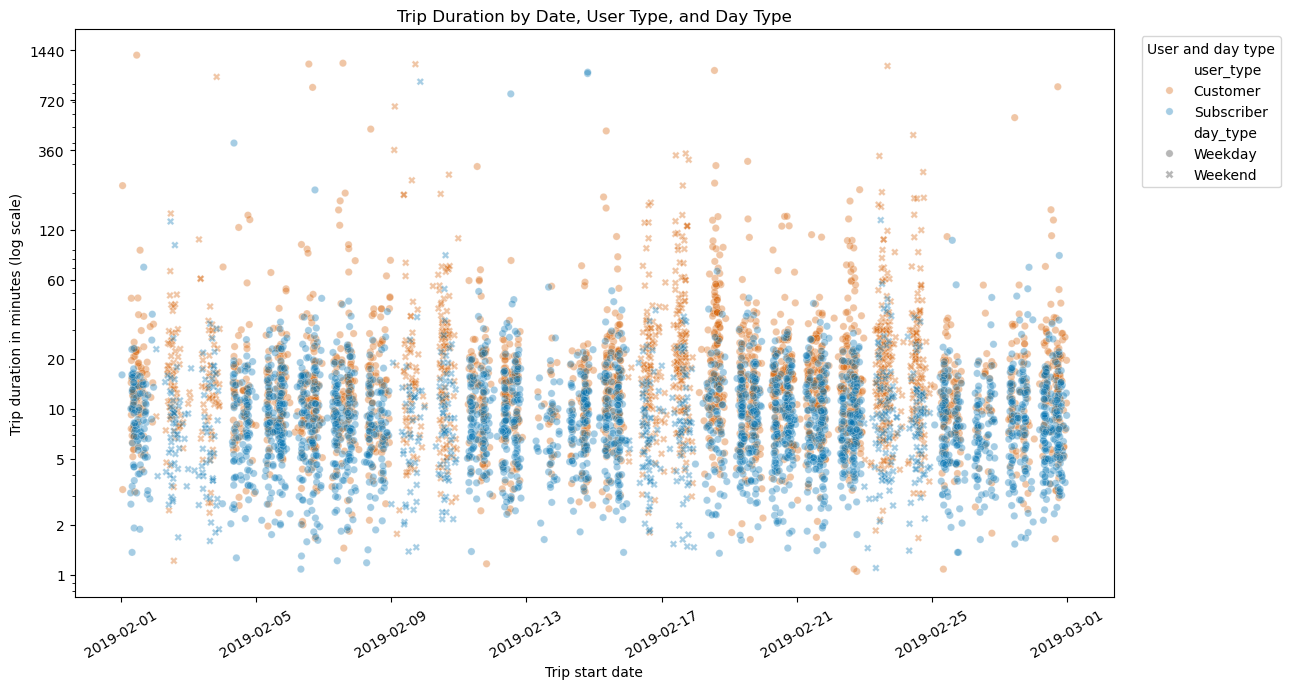

In [18]:
#Visualization 

scatter_sample = (bikes.groupby("user_type", group_keys=False).sample(n=3000, random_state=42))

palette = {
    "Subscriber": "#0072B2",
    "Customer": "#D55E00"
}

markers = {
    "Weekday": "o",
    "Weekend": "X"
}

plt.figure(figsize=(13, 7))

sns.scatterplot(
    data=scatter_sample,
    x="start_time",
    y="duration_min",
    hue="user_type",
    style="day_type",
    palette=palette,
    markers=markers,
    alpha=0.35,
    s=28
)

plt.yscale("log")
plt.title("Trip Duration by Date, User Type, and Day Type")
plt.xlabel("Trip start date")
plt.ylabel("Trip duration in minutes (log scale)")
plt.xticks(rotation=30)
ticks = [1, 2, 5, 10, 20, 60, 120, 360, 720, 1440]
plt.yticks(ticks, ticks)
plt.legend(
    title="User and day type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

## OBSERVATIONS
Customer trips generally appeared higher on the duration axis than subscriber trips, showing that customers tended to ride for longer periods. This difference was especially noticeable on weekends.

No clear increase or decrease in duration was observed over the month. The strongest pattern was the interaction between user type and day type: weekend customers took substantially longer trips, while subscriber duration remained stable.

### Talk about some of the relationships you observed in this part of the investigation. Were there features that strengthened each other in terms of looking at your feature(s) of interest?

> User type and day type strengthened each other when examining trip duration. Looking only at the day of the week showed that weekend trips were generally longer, but adding user type explained this pattern more clearly. Subscribers consistently took short trips on both weekdays and weekends, while customers took longer trips, particularly on weekends. Therefore, combining trip duration, user type, and day type provided a more complete explanation of how the bike-sharing service was used.

### Were there any interesting or surprising interactions between features?

> The most interesting interaction was between user type and day type. Customer trip duration increased considerably on weekends, from a median of about 12.4 minutes on weekdays to 16.1 minutes on weekends. Approximately 21.2% of weekend customer trips lasted longer than 30 minutes. In comparison, subscriber trip duration remained close to eight minutes throughout the week, and only 4.8% of weekend subscriber trips exceeded 30 minutes. This suggests that the longer overall weekend duration was mainly caused by customers, rather than by a general increase among all users.

## Conclusions

### Summary of findings

- Trip duration was strongly right-skewed. Most trips were short, with a median duration of approximately 8.6 minutes, while a small number lasted several hours.
- Bike usage was substantially higher on weekdays than on weekends. Thursday recorded the most trips, while Saturday and Sunday recorded the fewest.
- Weekend trips were generally longer than weekday trips, although fewer trips occurred on weekends.
- Subscribers usually took short trips, with median durations close to eight minutes throughout the week.
- Customers took longer trips than subscribers, especially on weekends. The median customer trip increased from approximately 12.4 minutes on weekdays to 16.1 minutes on weekends.
- The higher overall weekend duration was mainly driven by customer trips. Approximately 21.2% of weekend customer trips lasted longer than 30 minutes.
- Trip duration did not show a clear increasing or decreasing pattern during February.

### Reflection on the exploration

During the exploration, trip duration was converted from seconds to minutes to improve interpretation. The start-time variable was converted to a date-time format and used to derive the day of the week and weekday–weekend categories. Because trip duration contained a small number of extreme values, logarithmic scales and limited viewing ranges were used to make the main patterns visible without automatically deleting potentially valid trips.

The analysis progressed from examining individual distributions to comparing pairs of variables and finally investigating trip duration, timing, and user type together. The multivariate visualizations showed that user type was important for understanding the longer trips observed on weekends. Overall, the findings suggest that subscribers primarily used the service for short, routine weekday travel, while customers were more likely to take longer recreational trips on weekends.